In [1]:
# 1 - import thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import TensorDataset, DataLoader
from tensorflow.keras import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense

np.random.seed(42)
torch.manual_seed(42)
tf.random.set_seed(42)

device = torch.device("cpu")

In [2]:
# 2 - load data AAPL
df = pd.read_csv("AAPL_stock_data.csv")

df["Date"] = pd.to_datetime(df["Unnamed: 0"])
df = df.sort_values("Date").reset_index(drop=True)

features = ["open", "high", "low", "close", "adjclose", "volume"]
target = "close"

print("Shape:", df.shape)
print("Thời gian:", df["Date"].min().date(), "→", df["Date"].max().date())

Shape: (10971, 9)
Thời gian: 1980-12-12 → 2024-06-20


In [3]:
# 3 - phân tích tổng quan dữ liệu
print(df[["Date"] + features].describe().round(2))

                             Date      open      high       low     close  \
count                       10971  10971.00  10971.00  10971.00  10971.00   
mean   2002-09-07 00:10:53.650533     21.81     22.04     21.58     21.82   
min           1980-12-12 00:00:00      0.05      0.05      0.05      0.05   
25%           1991-10-17 12:00:00      0.30      0.30      0.29      0.30   
50%           2002-09-04 00:00:00      0.53      0.54      0.52      0.53   
75%           2013-07-27 12:00:00     19.92     20.13     19.73     19.91   
max           2024-06-20 00:00:00    217.59    220.20    213.00    216.67   
std                           NaN     44.98     45.46     44.53     45.02   

       adjclose        volume  
count  10971.00  1.097100e+04  
mean      21.05  3.187071e+08  
min        0.04  0.000000e+00  
25%        0.24  1.136572e+08  
50%        0.43  2.061696e+08  
75%       17.17  3.990980e+08  
max      216.67  7.421641e+09  
std       44.63  3.356215e+08  


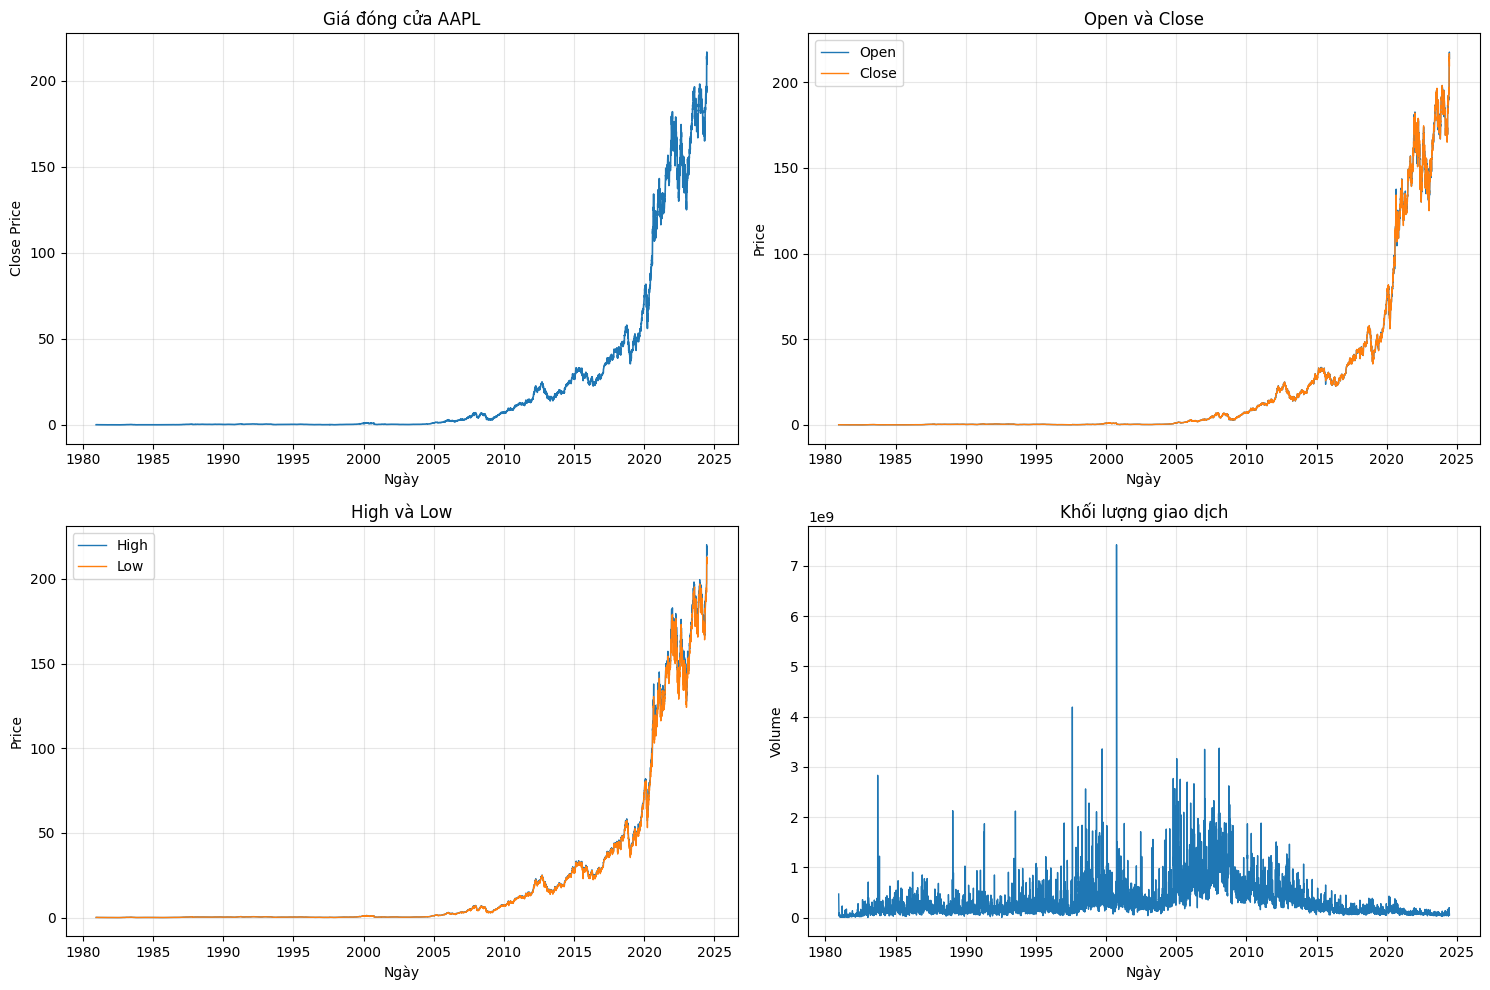

In [4]:
# 4 - visualization giá cổ phiếu AAPL
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(df["Date"], df["close"], linewidth=1.2)
axes[0, 0].set_title("Giá đóng cửa AAPL")
axes[0, 0].set_xlabel("Ngày")
axes[0, 0].set_ylabel("Close Price")
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(df["Date"], df["open"], label="Open", linewidth=1)
axes[0, 1].plot(df["Date"], df["close"], label="Close", linewidth=1)
axes[0, 1].set_title("Open và Close")
axes[0, 1].set_xlabel("Ngày")
axes[0, 1].set_ylabel("Price")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(df["Date"], df["high"], label="High", linewidth=1)
axes[1, 0].plot(df["Date"], df["low"], label="Low", linewidth=1)
axes[1, 0].set_title("High và Low")
axes[1, 0].set_xlabel("Ngày")
axes[1, 0].set_ylabel("Price")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(df["Date"], df["volume"], linewidth=1)
axes[1, 1].set_title("Khối lượng giao dịch")
axes[1, 1].set_xlabel("Ngày")
axes[1, 1].set_ylabel("Volume")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

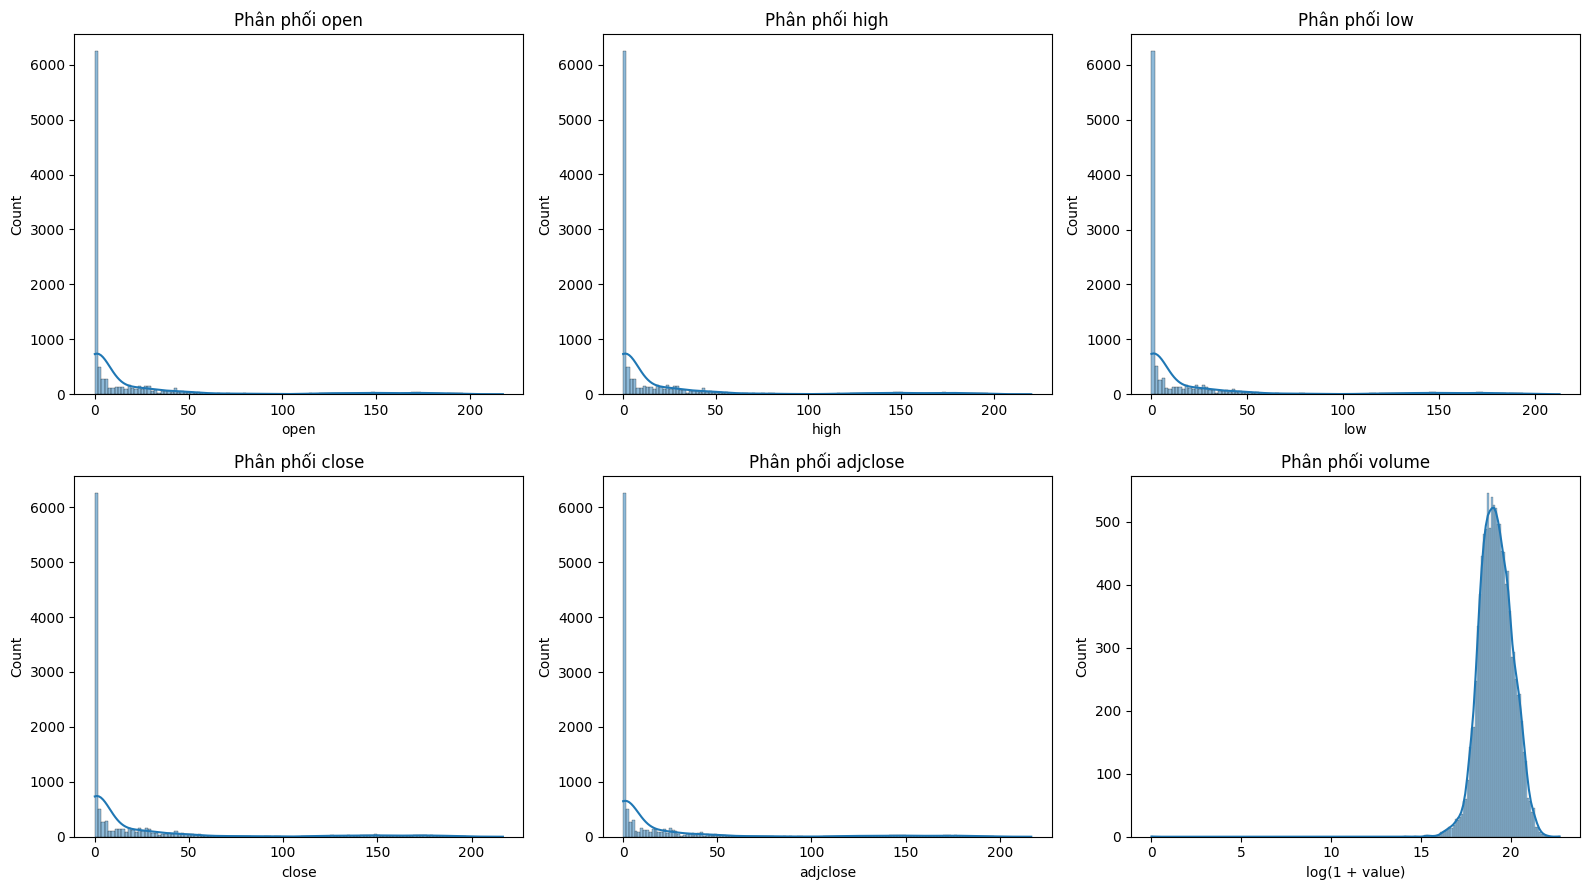

In [5]:
# 5 - visualization phân phối các biến
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, column in enumerate(features):
    ax = axes.flat[i]
    data = np.log1p(df[column]) if column == "volume" else df[column]
    sns.histplot(data, kde=True, ax=ax)
    ax.set_title(f"Phân phối {column}")
    ax.set_xlabel("log(1 + value)" if column == "volume" else column)

plt.tight_layout()
plt.show()

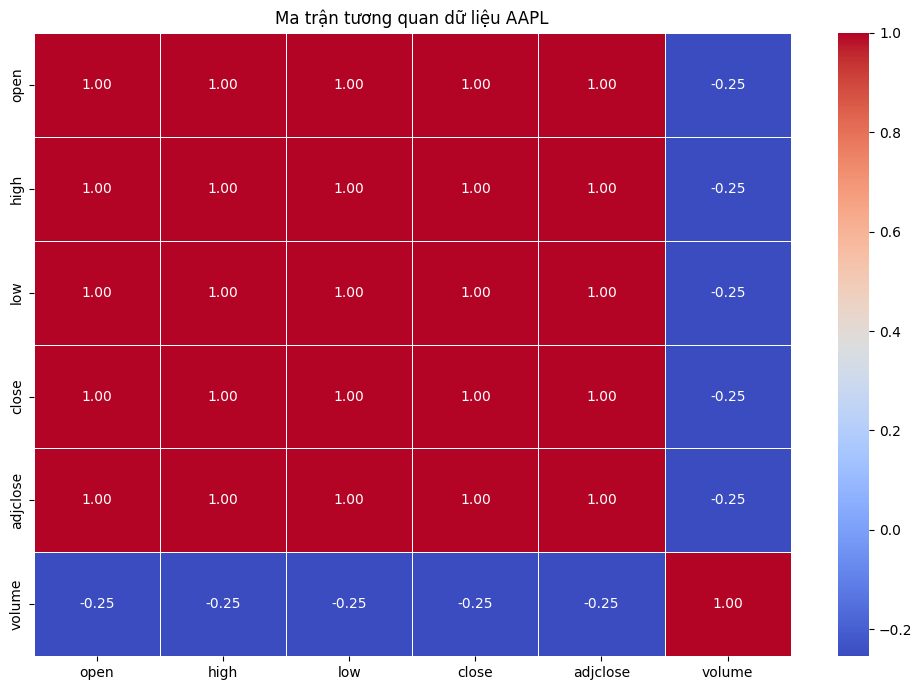

In [6]:
# 6 - visualization ma trận tương quan
plt.figure(figsize=(10, 7))

corr = df[features].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Ma trận tương quan dữ liệu AAPL")
plt.tight_layout()
plt.show()

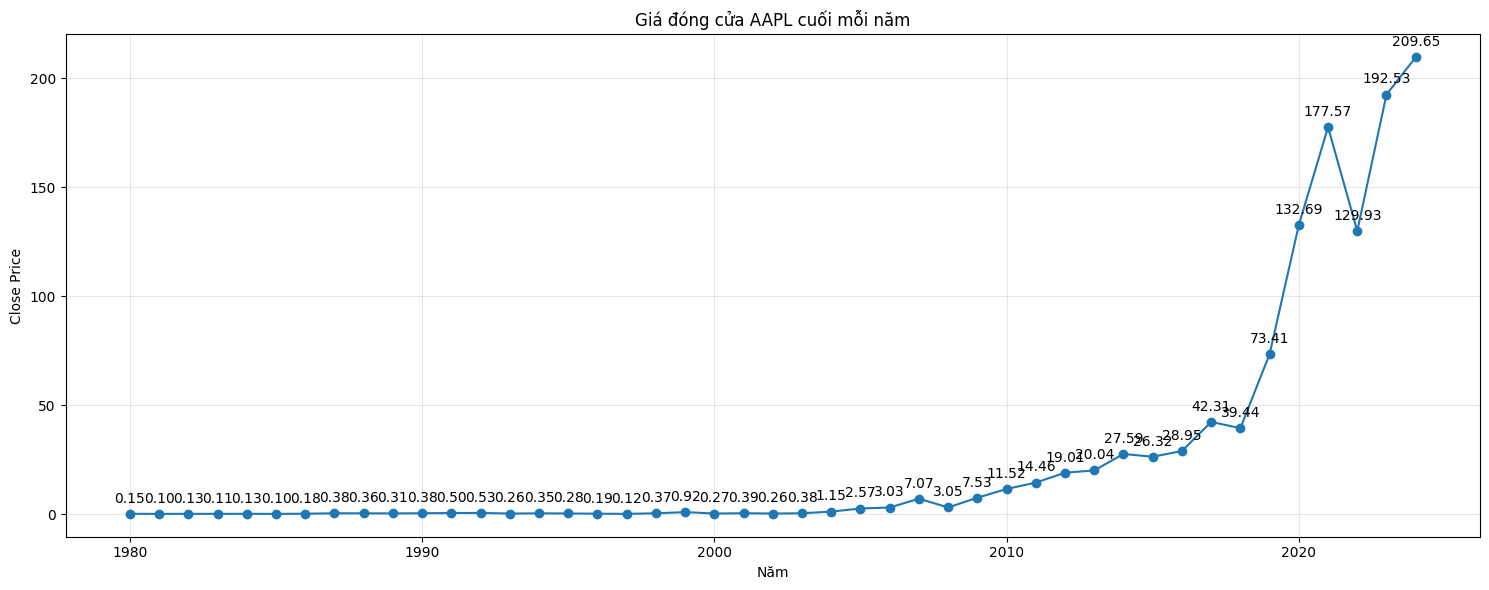

In [7]:
# 7 - visualization giá đóng cửa cuối mỗi năm
df["Year"] = df["Date"].dt.year

yearly_close = df.groupby("Year")["close"].last()

plt.figure(figsize=(15, 6))

plt.plot(
    yearly_close.index,
    yearly_close.values,
    marker="o",
    linewidth=1.5
)

for year, value in yearly_close.items():
    plt.annotate(
        f"{value:.2f}",
        (year, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.title("Giá đóng cửa AAPL cuối mỗi năm")
plt.xlabel("Năm")
plt.ylabel("Close Price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# 8 - chia dữ liệu theo thời gian
data = df[features].values.astype(np.float32)

train_end = int(len(data) * 0.70)
val_end = int(len(data) * 0.85)

train_data = data[:train_end]
val_data = data[train_end:val_end]
test_data = data[val_end:]

print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

Train: (7679, 6)
Validation: (1646, 6)
Test: (1646, 6)


In [9]:
# 9 - chuẩn hóa dữ liệu
scaler = MinMaxScaler()

scaler.fit(train_data)

scaled_data = scaler.transform(data)

In [10]:
# 10 - tạo sequence 30 phiên
sequence_length = 30
target_index = features.index("close")

X = []
y = []
dates = []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i, target_index])
    dates.append(df["Date"].iloc[i])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
dates = np.array(dates)

train_size = train_end - sequence_length
val_size = val_end - train_end

X_train = X[:train_size]
y_train = y[:train_size]

X_val = X[train_size:train_size + val_size]
y_val = y[train_size:train_size + val_size]

X_test = X[train_size + val_size:]
y_test = y[train_size + val_size:]

dates_test = dates[train_size + val_size:]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (7649, 30, 6)
X_val: (1646, 30, 6)
X_test: (1646, 30, 6)


In [11]:
# 11 - tạo Tensor và DataLoader PyTorch
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=32,
    shuffle=False
)

val_loader = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=32,
    shuffle=False
)

In [12]:
# 12 - xây dựng RNN, LSTM và GRU
class RNNModel(nn.Module):
    def __init__(self, input_size=6):
        super().__init__()
        self.rnn = nn.RNN(input_size, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class LSTMModel(nn.Module):
    def __init__(self, input_size=6):
        super().__init__()
        self.lstm = nn.LSTM(input_size, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

class GRUModel(nn.Module):
    def __init__(self, input_size=6):
        super().__init__()
        self.gru = nn.GRU(input_size, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :])

In [13]:
# 13 - hàm huấn luyện PyTorch
def train_model(model, train_loader, val_loader, epochs=40, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        train_loss = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            output = model(X_batch)
            loss = criterion(output, y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                output = model(X_batch)
                val_loss += criterion(output, y_batch).item()

        train_losses.append(train_loss / len(train_loader))
        val_losses.append(val_loss / len(val_loader))

    return train_losses, val_losses

In [14]:
# 14 - huấn luyện 3 mô hình PyTorch
models = {
    "Simple RNN": RNNModel(),
    "LSTM": LSTMModel(),
    "GRU": GRUModel()
}

histories = {}

for name, model in models.items():
    print(f"Training {name}...")
    histories[name] = train_model(
        model,
        train_loader,
        val_loader,
        epochs=40
    )

Training Simple RNN...
Training LSTM...
Training GRU...


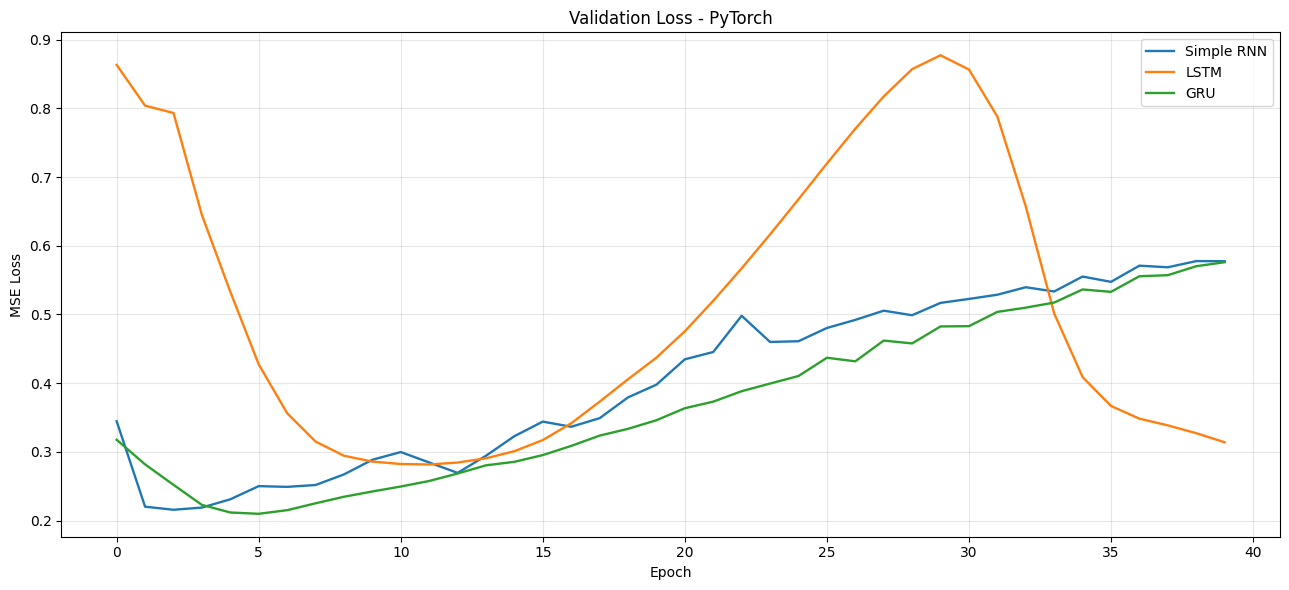

In [15]:
# 15 - visualization learning curves PyTorch
plt.figure(figsize=(13, 6))

for name, history in histories.items():
    train_loss, val_loss = history

    plt.plot(
        val_loss,
        label=name,
        linewidth=1.7
    )

plt.title("Validation Loss - PyTorch")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# 16 - đánh giá mô hình PyTorch
def evaluate_model(model, loader):
    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            predictions.extend(model(X_batch).numpy().flatten())
            actuals.extend(y_batch.numpy().flatten())

    return np.array(actuals), np.array(predictions)

pytorch_results = []
pytorch_predictions = {}

for name, model in models.items():
    actual, prediction = evaluate_model(model, test_loader)

    mae = mean_absolute_error(actual, prediction)
    rmse = np.sqrt(mean_squared_error(actual, prediction))
    r2 = r2_score(actual, prediction)

    pytorch_results.append([name, mae, rmse, r2])
    pytorch_predictions[name] = prediction

pytorch_results_df = pd.DataFrame(
    pytorch_results,
    columns=["Model", "MAE", "RMSE", "R2"]
)

pytorch_results_df

,Model,MAE,RMSE,R2
0,Simple RNN,7.271366,8.327440,-3.125880
1,LSTM,7.108325,8.213311,-3.013563
2,GRU,7.245023,8.290517,-3.089374


In [17]:
# 17 - chuyển prediction về giá Close thực tế
def inverse_close(values):
    temp = np.zeros((len(values), len(features)))
    temp[:, target_index] = values
    return scaler.inverse_transform(temp)[:, target_index]

actual_close = inverse_close(actual)

pytorch_predictions_real = {
    name: inverse_close(prediction)
    for name, prediction in pytorch_predictions.items()
}

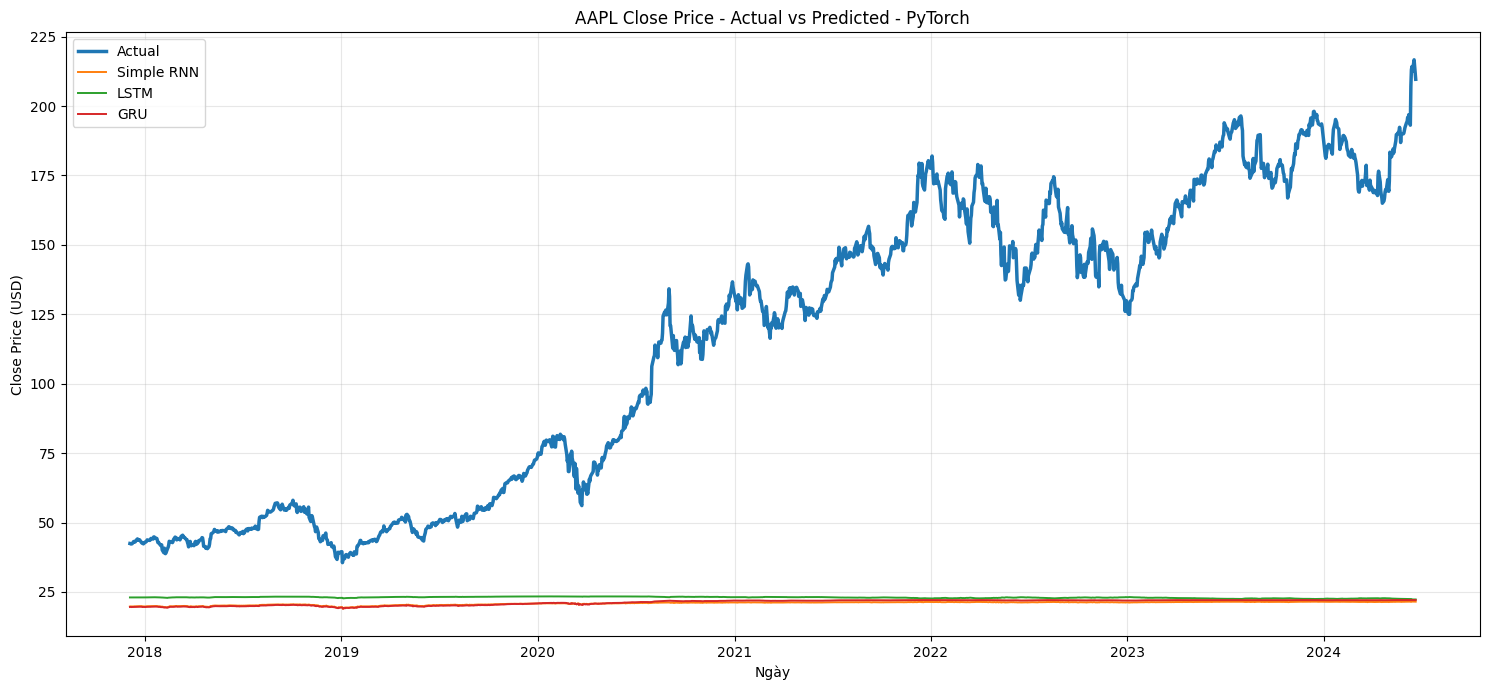

In [18]:
# 18 - visualization Actual và Predicted PyTorch
plt.figure(figsize=(15, 7))

plt.plot(
    dates_test,
    actual_close,
    label="Actual",
    linewidth=2.5
)

for name, prediction in pytorch_predictions_real.items():
    plt.plot(
        dates_test,
        prediction,
        label=name,
        linewidth=1.4
    )

plt.title("AAPL Close Price - Actual vs Predicted - PyTorch")
plt.xlabel("Ngày")
plt.ylabel("Close Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

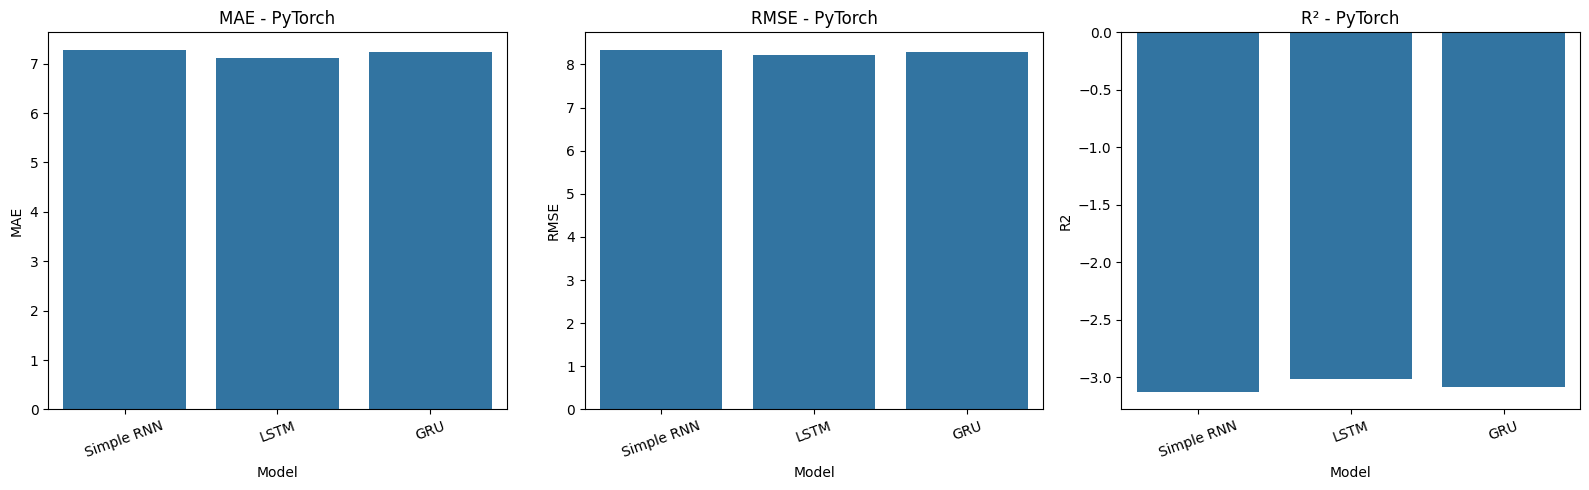

In [19]:
# 19 - visualization metrics PyTorch
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=pytorch_results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE - PyTorch")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=pytorch_results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE - PyTorch")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(data=pytorch_results_df, x="Model", y="R2", ax=axes[2])
axes[2].set_title("R² - PyTorch")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [20]:
# 20 - xây dựng RNN, LSTM và GRU Keras
def build_rnn():
    model = Sequential([
        SimpleRNN(32, input_shape=(sequence_length, len(features))),
        Dense(1)
    ])
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model

def build_lstm():
    model = Sequential([
        LSTM(32, input_shape=(sequence_length, len(features))),
        Dense(1)
    ])
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model

def build_gru():
    model = Sequential([
        GRU(32, input_shape=(sequence_length, len(features))),
        Dense(1)
    ])
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model

In [21]:
# 21 - huấn luyện 3 mô hình Keras
keras_models = {
    "Simple RNN": build_rnn(),
    "LSTM": build_lstm(),
    "GRU": build_gru()
}

keras_histories = {}

for name, model in keras_models.items():
    print(f"Training {name}...")

    keras_histories[name] = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=32,
        verbose=0
    )

C:\Users\vuthu\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training Simple RNN...
Training LSTM...
Training GRU...


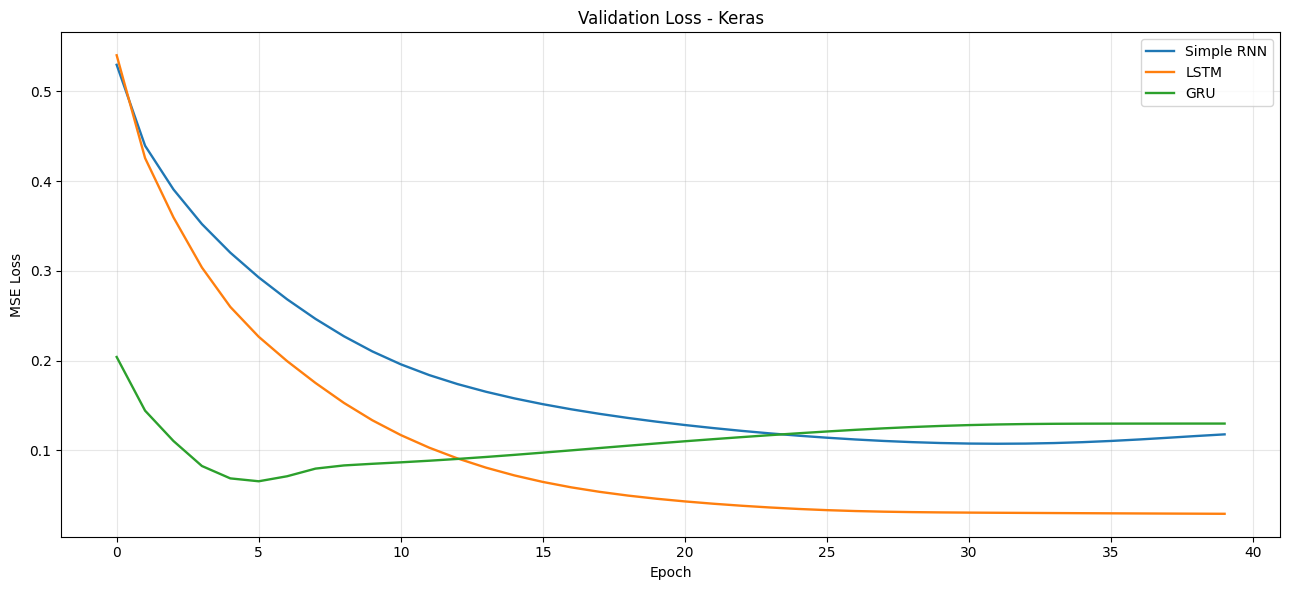

In [22]:
# 22 - visualization learning curves Keras
plt.figure(figsize=(13, 6))

for name, history in keras_histories.items():
    plt.plot(
        history.history["val_loss"],
        label=name,
        linewidth=1.7
    )

plt.title("Validation Loss - Keras")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# 23 - đánh giá mô hình Keras
keras_results = []
keras_predictions = {}

for name, model in keras_models.items():
    prediction = model.predict(
        X_test,
        verbose=0
    ).flatten()

    mae = mean_absolute_error(y_test, prediction)
    rmse = np.sqrt(mean_squared_error(y_test, prediction))
    r2 = r2_score(y_test, prediction)

    keras_results.append([name, mae, rmse, r2])
    keras_predictions[name] = prediction

keras_results_df = pd.DataFrame(
    keras_results,
    columns=["Model", "MAE", "RMSE", "R2"]
)

keras_results_df

,Model,MAE,RMSE,R2
0,Simple RNN,6.064880,7.143760,-2.036318
1,LSTM,5.033667,6.160613,-1.258090
2,GRU,5.987375,7.068714,-1.972860


In [24]:
# 24 - chuyển prediction Keras về giá Close thực tế
keras_predictions_real = {
    name: inverse_close(prediction)
    for name, prediction in keras_predictions.items()
}

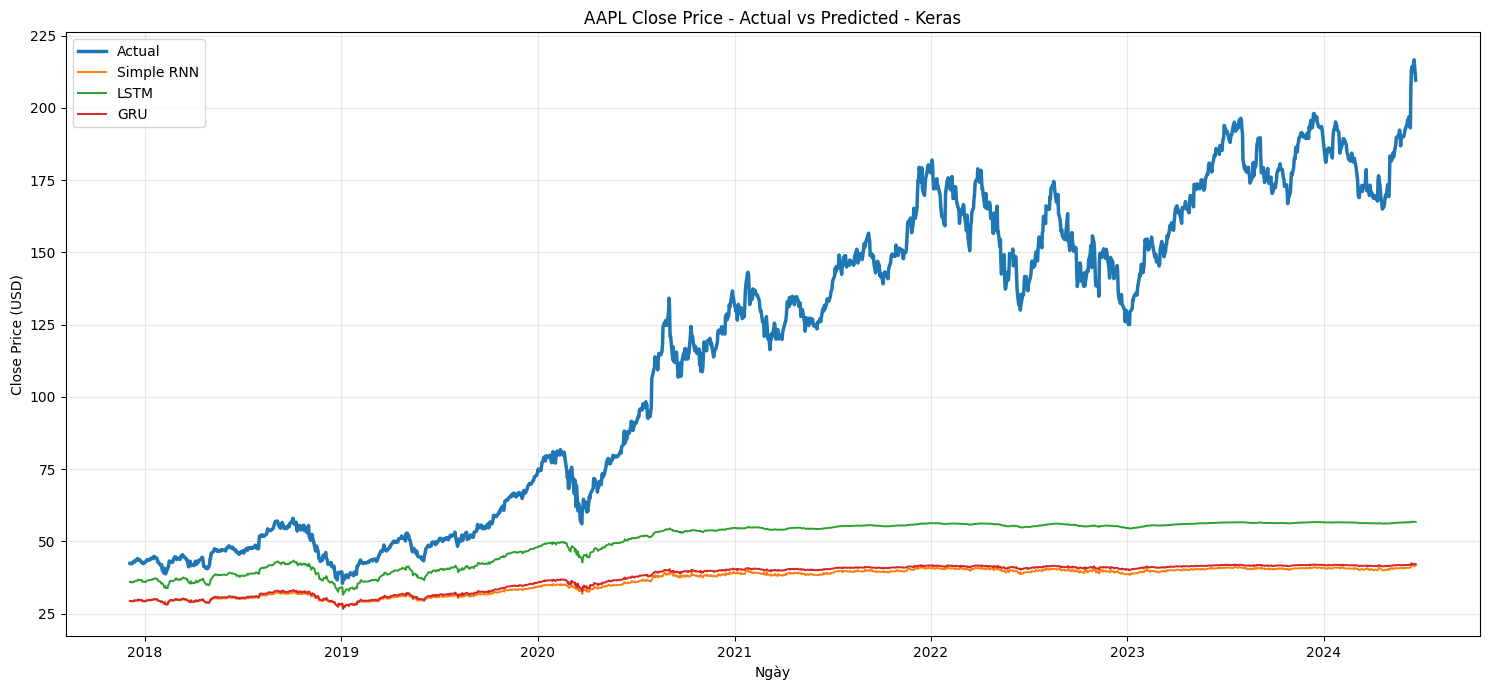

In [25]:
# 25 - visualization Actual và Predicted Keras
plt.figure(figsize=(15, 7))

plt.plot(
    dates_test,
    actual_close,
    label="Actual",
    linewidth=2.5
)

for name, prediction in keras_predictions_real.items():
    plt.plot(
        dates_test,
        prediction,
        label=name,
        linewidth=1.4
    )

plt.title("AAPL Close Price - Actual vs Predicted - Keras")
plt.xlabel("Ngày")
plt.ylabel("Close Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

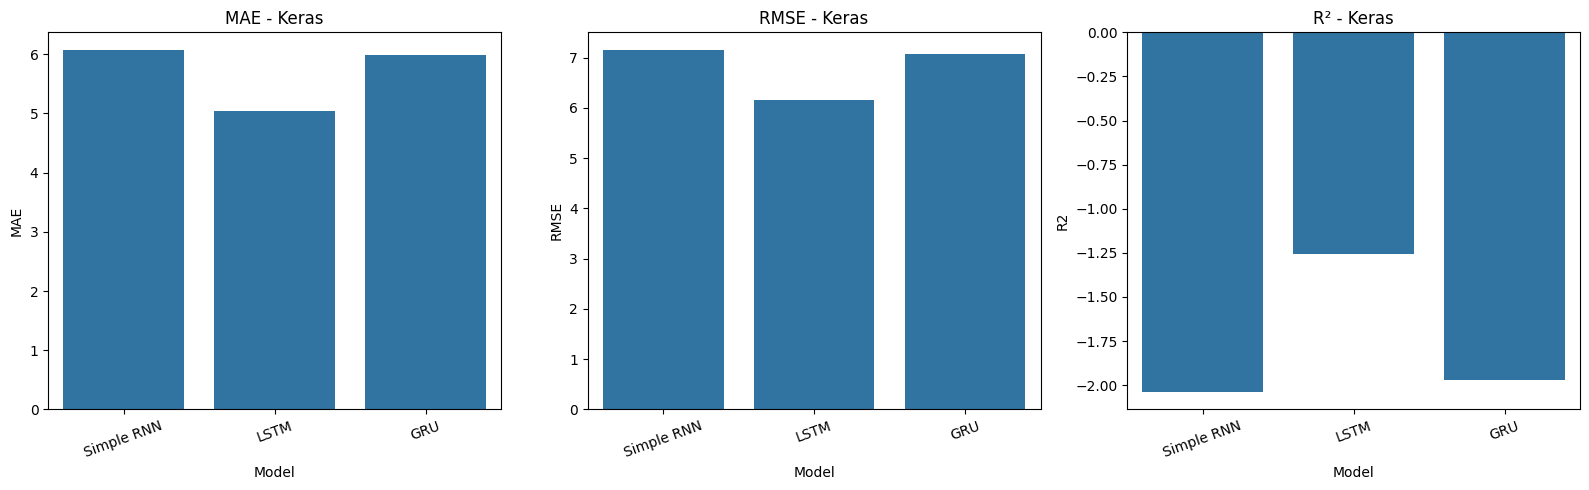

In [26]:
# 26 - visualization metrics Keras
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=keras_results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE - Keras")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=keras_results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE - Keras")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(data=keras_results_df, x="Model", y="R2", ax=axes[2])
axes[2].set_title("R² - Keras")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [27]:
# 27 - tổng hợp kết quả PyTorch và Keras
pytorch_compare = pytorch_results_df.copy()
pytorch_compare["Framework"] = "PyTorch"

keras_compare = keras_results_df.copy()
keras_compare["Framework"] = "Keras"

comparison = pd.concat(
    [pytorch_compare, keras_compare],
    ignore_index=True
)

comparison = comparison[
    ["Framework", "Model", "MAE", "RMSE", "R2"]
]

comparison

,Framework,Model,MAE,RMSE,R2
0,PyTorch,Simple RNN,7.271366,8.327440,-3.125880
1,PyTorch,LSTM,7.108325,8.213311,-3.013563
2,PyTorch,GRU,7.245023,8.290517,-3.089374
3,Keras,Simple RNN,6.064880,7.143760,-2.036318
4,Keras,LSTM,5.033667,6.160613,-1.258090
5,Keras,GRU,5.987375,7.068714,-1.972860


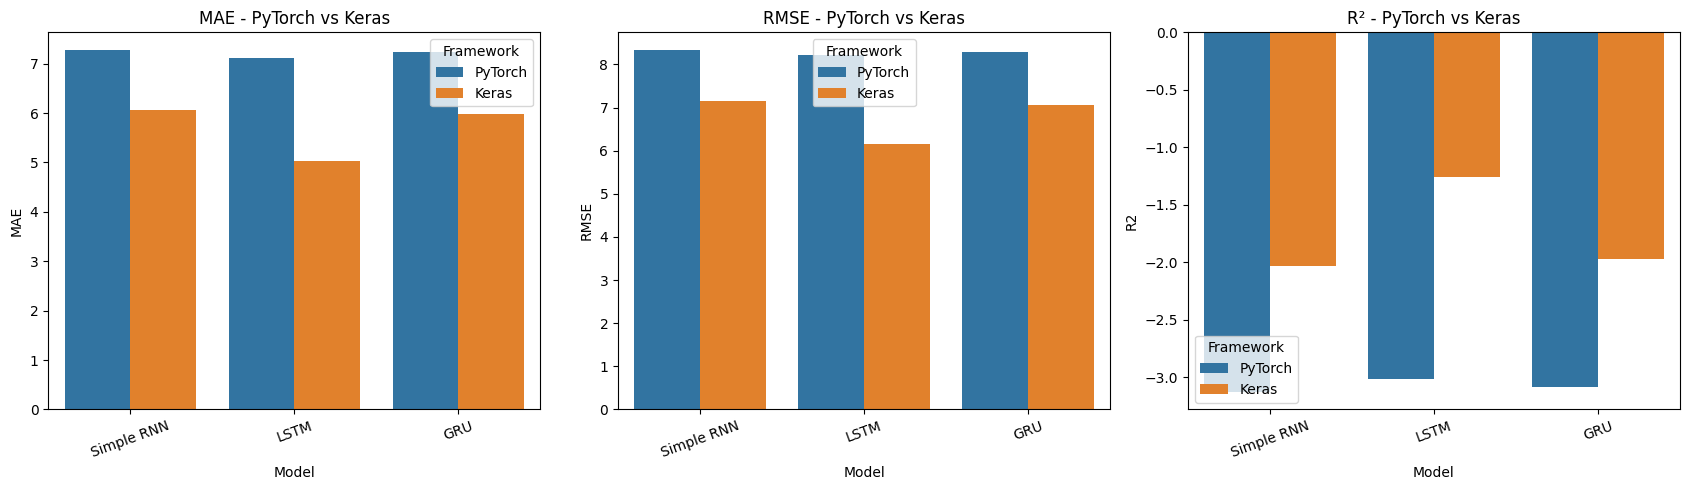

In [28]:
# 28 - visualization so sánh PyTorch và Keras
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="MAE",
    hue="Framework",
    ax=axes[0]
)
axes[0].set_title("MAE - PyTorch vs Keras")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=comparison,
    x="Model",
    y="RMSE",
    hue="Framework",
    ax=axes[1]
)
axes[1].set_title("RMSE - PyTorch vs Keras")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(
    data=comparison,
    x="Model",
    y="R2",
    hue="Framework",
    ax=axes[2]
)
axes[2].set_title("R² - PyTorch vs Keras")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

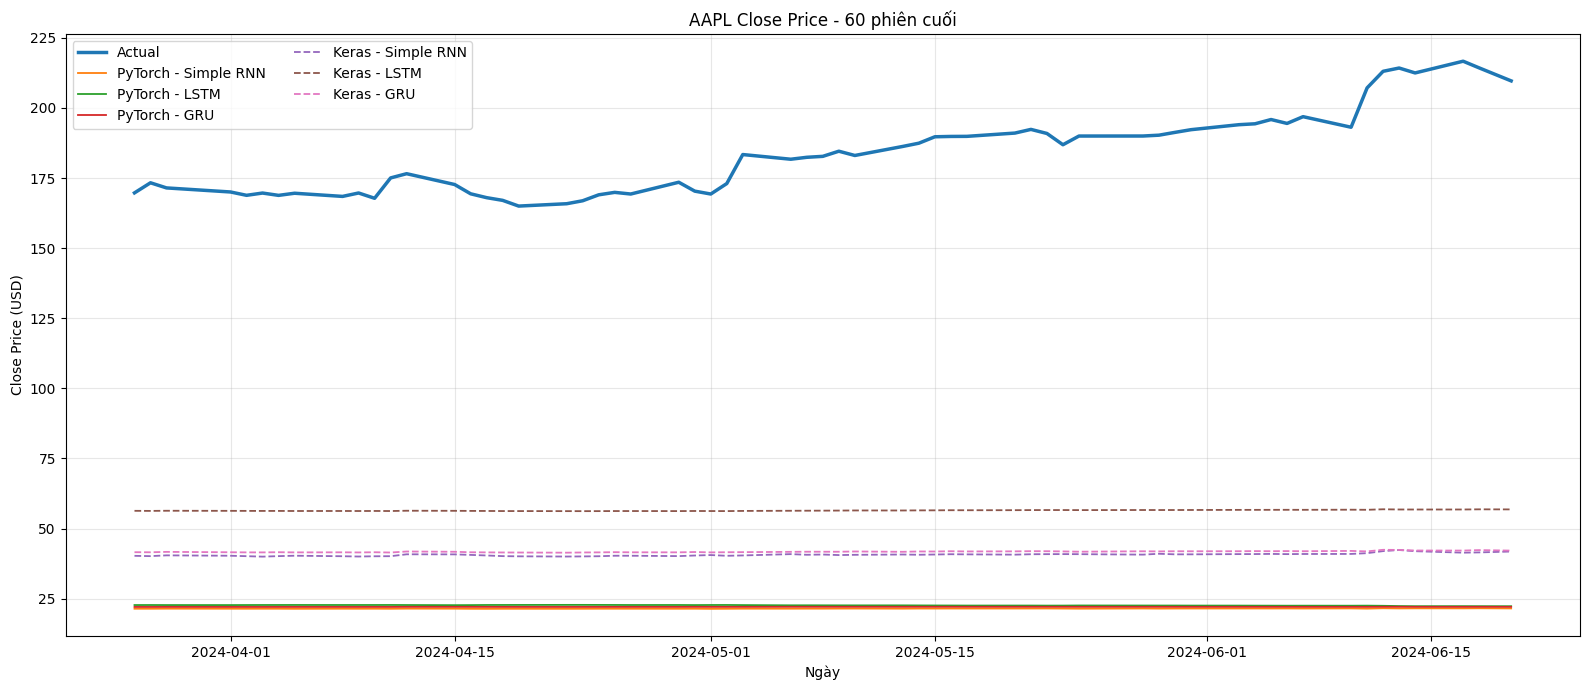

In [29]:
# 29 - visualization 60 phiên giao dịch cuối
last_n = 60

plt.figure(figsize=(16, 7))

plt.plot(
    dates_test[-last_n:],
    actual_close[-last_n:],
    label="Actual",
    linewidth=2.5
)

for name, prediction in pytorch_predictions_real.items():
    plt.plot(
        dates_test[-last_n:],
        prediction[-last_n:],
        label=f"PyTorch - {name}",
        linewidth=1.3
    )

for name, prediction in keras_predictions_real.items():
    plt.plot(
        dates_test[-last_n:],
        prediction[-last_n:],
        linestyle="--",
        label=f"Keras - {name}",
        linewidth=1.3
    )

plt.title("AAPL Close Price - 60 phiên cuối")
plt.xlabel("Ngày")
plt.ylabel("Close Price (USD)")
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

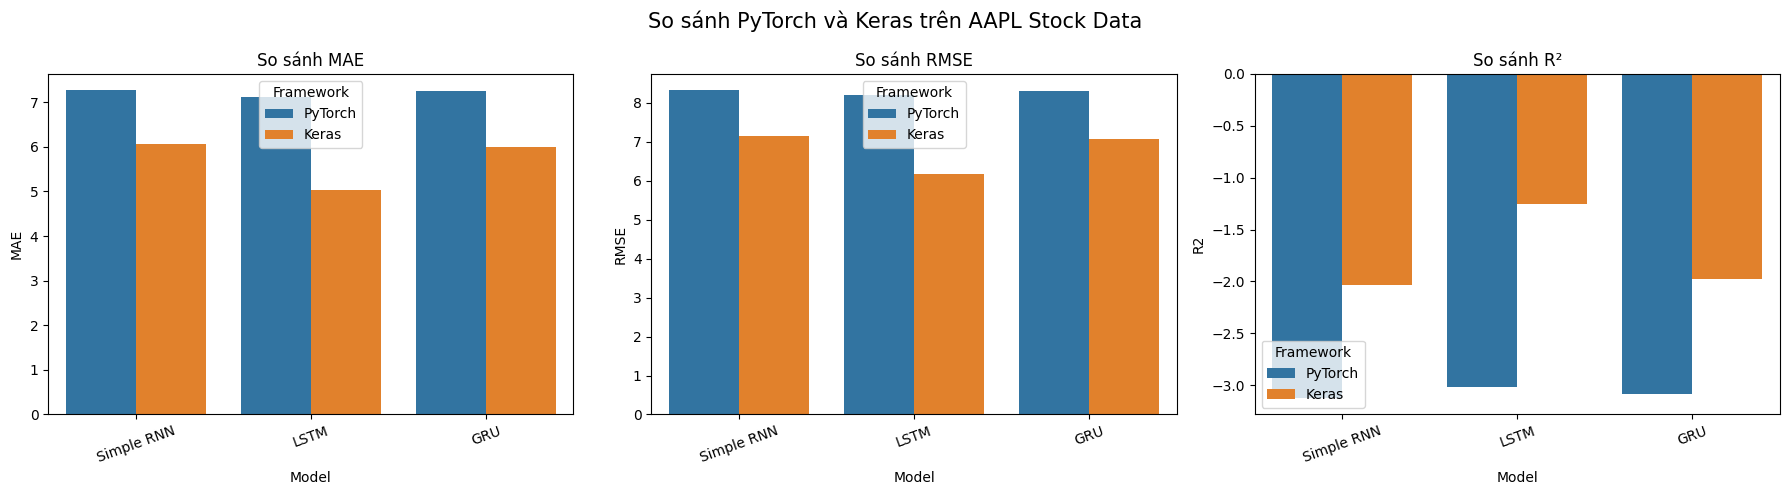

In [30]:
# 30 - visualization tổng hợp kết quả
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="MAE",
    hue="Framework",
    ax=axes[0]
)
axes[0].set_title("So sánh MAE")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=comparison,
    x="Model",
    y="RMSE",
    hue="Framework",
    ax=axes[1]
)
axes[1].set_title("So sánh RMSE")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(
    data=comparison,
    x="Model",
    y="R2",
    hue="Framework",
    ax=axes[2]
)
axes[2].set_title("So sánh R²")
axes[2].tick_params(axis="x", rotation=20)

plt.suptitle("So sánh PyTorch và Keras trên AAPL Stock Data", fontsize=15)
plt.tight_layout()
plt.show()